$\Huge\textbf{FROG Analysis}$

$\huge\textbf{By Austin Hayes}$

Within this file (file: "2_FROGAnalysis.ipynb"), the main focus will be to utilize StackGP within the FROG_ENV to get the equation that best fits our data, from here we will begin cross checking this result against the real data we should have imported within our "1_NewLoadFrogTrace.ipynb" file. 
     
  $\textbf {1.}$ Enter the FROG_ENV environment by clicking kernel -> change kernel -> Python (FROG_ENV).

     
  $\textbf {2.}$ Import the FROG.py package utilizing the following code: import FROG as frog

     
  $\textbf {3.}$ Retrieve the stored dataframes from the "1_NewLoadFrogTrace.ipynb" file, these are: new_df, new_wave, and new_time by utilizing the following code: 

$\hspace{1cm}\textbf {A.}$ %store -r new_df 

$\hspace{1cm}\textbf {B.}$ %store -r new_wave (in units of nm)

$\hspace{1cm}\textbf {C.}$ %store -r new_time (in units of fs)

$\hspace{1cm}\textbf {D.}$ %store -r freq (in units of THz)

  $\textbf {4.}$ Retrieve the electric field vs. time to get an accurate electric field equation for a single light pulse, ie. the waveform. Do this by entering the field class, then the frog_projection_new() function, where the only input you need is the intensities dataframe from notebook 1, followed by the maximum number of iterations you want the projection to run over (default 1000), as well as the threshold error (root mean squared method, default = 0.05). 

  $\textbf {5.}$ Calculate the full width half maximum from the calc_time() function, where your inputs are the wavelengths (new df from notebook 1) and the E field values you got in the last step. The full width half maximum (fwhm) is the zeroth index, with the time step size being the returned value at index 1.

  $\textbf {6.}$ Calculate the times by running the line: time = np.linspace(0, dt*len(E_field), len(E_field)), then use matplotlib to plot out the waveform. (E field vs. time)


In [13]:
import FROG as frog

In [14]:
#Retrieving stored dataframe, wavelengths, and times.

%store -r new_df
%store -r new_wave 
%store -r new_time 
%store -r freq 

In [24]:
#Showcasing the df

new_df

,0.000000,2.015152,4.030303,6.045455,8.060606,10.075758,12.090909,14.106061,16.121212,18.136364,...,247.863636,249.878788,251.893939,253.909091,255.924242,257.939394,259.954545,261.969697,263.984848,266.000000
882.715146,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,...,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755
881.722964,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,...,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480
880.733131,-4.253016,-18.452342,7.106445,23.009689,-29.811802,-0.845178,-4.253016,-3.117070,-22.428153,30.961312,...,-16.180450,-1.413151,-25.268018,-10.500719,-12.772611,-17.316396,0.858741,-46.850993,-1.981124,-4.253016
879.745639,-75.249645,-40.603290,-41.739236,-36.059506,-73.545726,-40.603290,-78.089510,-50.826804,-46.850993,-37.763425,...,-46.850993,-86.609105,-67.298022,-61.050319,-32.651667,-45.715047,-66.162076,-61.050319,-66.162076,-24.700045
878.760479,-53.666670,-42.875182,-61.618292,-48.554912,-40.035317,-72.409780,-37.195452,-34.923560,-34.923560,-56.506535,...,-71.841806,-61.050319,-66.730049,-44.579101,-41.739236,-49.122885,-14.476531,-47.418966,-60.482346,-60.482346
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295.535897,420.590810,420.590810,417.182972,414.911080,439.333920,433.654189,433.654189,395.599997,427.406486,357.545804,...,412.639187,395.599997,410.935268,435.926082,409.231349,413.207160,435.358109,383.672563,395.032024,407.527430
295.456063,406.391484,430.246351,413.775133,406.391484,418.318918,388.784320,384.240536,417.182972,417.182972,419.454864,...,370.609183,406.391484,405.823511,434.222163,367.769318,382.536617,402.415673,409.799322,422.862702,425.702567
295.376290,426.270540,427.974459,407.527430,417.750945,427.974459,422.294729,392.760131,399.575808,413.207160,441.605812,...,358.681750,402.415673,420.022837,405.823511,388.784320,383.672563,389.920266,417.750945,401.847700,387.080401
295.296576,426.270540,427.974459,407.527430,417.750945,427.974459,422.294729,392.760131,399.575808,413.207160,441.605812,...,358.681750,402.415673,420.022837,405.823511,388.784320,383.672563,389.920266,417.750945,401.847700,387.080401


In [16]:
#Converting to frequency instead of wavelength as the row labels

new_df.index = freq

new_df

,0.000000,2.015152,4.030303,6.045455,8.060606,10.075758,12.090909,14.106061,16.121212,18.136364,...,247.863636,249.878788,251.893939,253.909091,255.924242,257.939394,259.954545,261.969697,263.984848,266.000000
882.715146,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,...,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755,-2284.096755
881.722964,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,...,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480,24939.986480
880.733131,-4.253016,-18.452342,7.106445,23.009689,-29.811802,-0.845178,-4.253016,-3.117070,-22.428153,30.961312,...,-16.180450,-1.413151,-25.268018,-10.500719,-12.772611,-17.316396,0.858741,-46.850993,-1.981124,-4.253016
879.745639,-75.249645,-40.603290,-41.739236,-36.059506,-73.545726,-40.603290,-78.089510,-50.826804,-46.850993,-37.763425,...,-46.850993,-86.609105,-67.298022,-61.050319,-32.651667,-45.715047,-66.162076,-61.050319,-66.162076,-24.700045
878.760479,-53.666670,-42.875182,-61.618292,-48.554912,-40.035317,-72.409780,-37.195452,-34.923560,-34.923560,-56.506535,...,-71.841806,-61.050319,-66.730049,-44.579101,-41.739236,-49.122885,-14.476531,-47.418966,-60.482346,-60.482346
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295.535897,420.590810,420.590810,417.182972,414.911080,439.333920,433.654189,433.654189,395.599997,427.406486,357.545804,...,412.639187,395.599997,410.935268,435.926082,409.231349,413.207160,435.358109,383.672563,395.032024,407.527430
295.456063,406.391484,430.246351,413.775133,406.391484,418.318918,388.784320,384.240536,417.182972,417.182972,419.454864,...,370.609183,406.391484,405.823511,434.222163,367.769318,382.536617,402.415673,409.799322,422.862702,425.702567
295.376290,426.270540,427.974459,407.527430,417.750945,427.974459,422.294729,392.760131,399.575808,413.207160,441.605812,...,358.681750,402.415673,420.022837,405.823511,388.784320,383.672563,389.920266,417.750945,401.847700,387.080401
295.296576,426.270540,427.974459,407.527430,417.750945,427.974459,422.294729,392.760131,399.575808,413.207160,441.605812,...,358.681750,402.415673,420.022837,405.823511,388.784320,383.672563,389.920266,417.750945,401.847700,387.080401


In [6]:
new_df.size

272384

WORK STILL IN PROGRESS BELOW:

Still attempting to get the correct electric field values to get the overall shape and length of said pulse. 

In [33]:
freq, tau = new_df.shape

In [17]:
I_meas = new_df.to_numpy() if hasattr(new_df, 'to_numpy') else new_df
N_f, N_t = new_df.shape

In [25]:
#Utilizing the frog_projection_new function to obtain the E field values from intensity.
import matplotlib.pyplot as plt
import pandas as pd

E_field = field.frog_projection_new(new_df)[0]

I = field.frog_projection_new(new_df)[2]

I_calc = pd.DataFrame(I)

I_calc.index = freq
I_calc.columns = new_time

I_calc 


Converged at iteration 2 with RMS: 0.0445
Converged at iteration 2 with RMS: 0.0458


,0.000000,2.015152,4.030303,6.045455,8.060606,10.075758,12.090909,14.106061,16.121212,18.136364,...,247.863636,249.878788,251.893939,253.909091,255.924242,257.939394,259.954545,261.969697,263.984848,266.000000
882.715146,0.186946,0.684508,1.057511,0.740726,1.798392,0.321899,0.535000,0.618115,1.153143,0.436443,...,0.743060,0.436443,1.153143,0.618115,0.535000,0.321899,1.798392,0.740726,1.057511,0.643451
881.722964,0.392539,0.399448,2.450123,0.870794,2.631513,0.255754,1.481378,0.276957,2.183240,0.022957,...,1.374756,0.022957,2.183240,0.276957,1.481378,0.255754,2.631513,0.870794,2.450123,1.902987
880.733131,0.912867,0.349349,3.569559,1.503179,3.402707,0.316998,2.912338,0.174547,3.649254,0.137619,...,2.489872,0.137619,3.649254,0.174547,2.912338,0.316998,3.402707,1.503179,3.569559,2.578734
879.745639,1.573836,0.600157,3.811638,2.264997,3.464011,0.709146,4.048310,0.540714,4.894241,0.569856,...,3.652312,0.569856,4.894241,0.540714,4.048310,0.709146,3.464011,2.264997,3.811638,2.090198
878.760479,2.179553,1.257293,3.756907,3.020156,3.316077,1.243584,5.142835,1.445777,6.518463,0.944692,...,5.111976,0.944692,6.518463,1.445777,5.142835,1.243584,3.316077,3.020156,3.756907,1.835937
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295.535897,2.763133,2.679672,0.721813,0.605154,0.538919,0.330968,1.404943,0.211069,0.739141,0.366419,...,2.473911,0.366419,0.739141,0.211069,1.404943,0.330968,0.538919,0.605154,0.721813,1.061501
295.456063,2.046337,2.715714,0.486399,0.855670,0.373405,0.600371,1.345710,0.306985,0.818049,0.479403,...,2.124860,0.479403,0.818049,0.306985,1.345710,0.600371,0.373405,0.855670,0.486399,1.488481
295.376290,1.376426,2.546478,0.686547,1.024574,1.118498,0.919495,1.790089,0.425040,1.201396,0.462967,...,2.426609,0.462967,1.201396,0.425040,1.790089,0.919495,1.118498,1.024574,0.686547,1.744180
295.296576,0.636284,1.668760,0.361344,0.974828,0.898549,0.737188,1.531874,0.370759,0.664683,0.445222,...,1.345696,0.445222,0.664683,0.370759,1.531874,0.737188,0.898549,0.974828,0.361344,1.098802


In [27]:
#Retrieving the length of the pulse, ie. the full width half maximum (fwhm)

fwhm, dt = field.calc_time(new_wave, E_field)
fwhm = float(fwhm) #for data_1400_after_bs should be closer to 40 fs, not 260.


Time step: 1.7021328083714748 fs
Pulse duration (fwhm): 534.4697018286431 fs


In [30]:
#setting my time range based on the number of steps the function is taking, to get the associated E field value at said time.
import numpy as np
time = np.linspace(0, dt*len(E_field), len(E_field))

Text(0.5, 1.0, 'E field vs. Time (fs)')

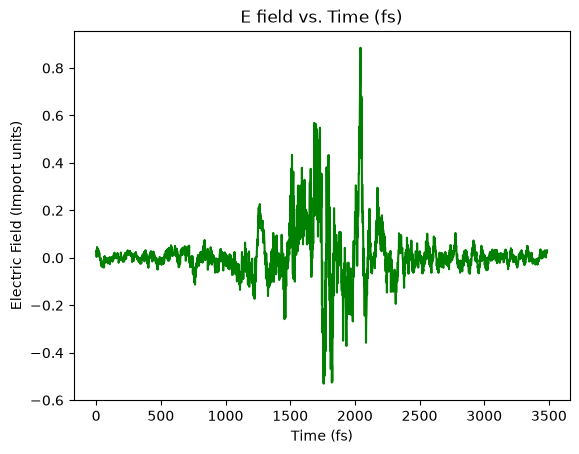

In [31]:
plt.plot(time, E_field, color = 'Green')
#plt.xlim(1400, 1700)
plt.xlabel('Time (fs)')
plt.ylabel('Electric Field (Import units)')
plt.title('E field vs. Time (fs)')



Pulse should be a little more symmetric across the time axis. Shouldn't be as random with the E field magnitudes. 


Need to set the carrier envelope phase to zero, as sort of an assumption. 